# Fault Injection and Validation — Magnet Power Supply Digital Twin

**Notebook 4 of 4**

This notebook builds on the pipeline established in the previous three notebooks:

1. `Digital_Twin_Data_Generation.ipynb` — physics-based healthy dataset generation.
2. `LSTM_Training_MagnetPowerSupply.ipynb` — LSTM training for temperature prediction.
3. `Anomaly_Detection_Healthy_Operation.ipynb` — residual-based anomaly threshold derivation on healthy data.

In this notebook we:

- Generate **four physically realistic fault scenarios** using the same lumped thermal
  digital-twin equations as the healthy dataset (only the relevant physical parameters
  are changed per fault — temperatures are never hand-scripted).
- Load the **already-trained** LSTM model (`lstm_temperature_model.keras`) — **no retraining**.
- Run the model on the faulty data, compute prediction residuals, and apply the
  **same anomaly threshold** derived in Notebook 3.
- Evaluate detection performance (precision/recall/F1/confusion matrix) and produce
  publication-quality figures.
- Discuss the engineering significance of the results.

> **Environment note:** This notebook is designed to run top-to-bottom in Google Colab.
> It expects `magnet_power_supply_dataset.csv` and `lstm_temperature_model.keras` to be
> present in the Colab working directory (upload them via the Colab file browser, or
> mount Google Drive and adjust `DATA_DIR` below).

## 1. Setup and Imports

In [3]:
# --- Core scientific stack ---
import os
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

# --- Modeling / preprocessing ---
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score, f1_score,
    ConfusionMatrixDisplay
)
from scipy.optimize import curve_fit
from scipy.interpolate import interp1d
from scipy.integrate import solve_ivp

# --- Visualization ---
import matplotlib.pyplot as plt
import matplotlib as mpl

# Publication-quality plotting defaults
mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.figsize": (9, 5),
})

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("All libraries imported successfully.")

TensorFlow version: 2.20.0
All libraries imported successfully.


## 2. Load Artifacts From Previous Notebooks

We load:

- The **healthy dataset** (`magnet_power_supply_dataset.csv`) — used both as the physical
  basis for fault simulation (same current profile, same digital twin) and as the
  healthy baseline for evaluation.
- The **trained LSTM model** (`lstm_temperature_model.keras`) — loaded as-is, **not retrained**.
- The **anomaly threshold** from Notebook 3, if it was saved to disk
  (`anomaly_threshold.json`). If it isn't found, we recompute it using the same
  methodology (mean + 3·std of the healthy prediction residuals) so the notebook can
  still run standalone, but the saved value always takes priority.

In [4]:
DATA_DIR = "."  # change if files are stored elsewhere (e.g. after mounting Drive)

HEALTHY_CSV_PATH = os.path.join(DATA_DIR, "magnet_power_supply_dataset.csv")
MODEL_PATH = os.path.join(DATA_DIR, "lstm_temperature_model.keras")
THRESHOLD_PATH = os.path.join(DATA_DIR, "anomaly_threshold.json")

assert os.path.exists(HEALTHY_CSV_PATH), (
    f"Could not find {HEALTHY_CSV_PATH}. Upload the healthy dataset from Notebook 1 "
    "to the Colab working directory before continuing."
)
assert os.path.exists(MODEL_PATH), (
    f"Could not find {MODEL_PATH}. Upload the trained model from Notebook 2 "
    "to the Colab working directory before continuing."
)

healthy_df = pd.read_csv(HEALTHY_CSV_PATH)
healthy_df = healthy_df.sort_values("Time_s").reset_index(drop=True)

required_cols = {"Time_s", "Current_A", "TrueTemperature_C"}
missing = required_cols - set(healthy_df.columns)
assert not missing, f"Healthy dataset is missing required columns: {missing}"

print(f"Healthy dataset loaded: {healthy_df.shape[0]} samples, columns = {list(healthy_df.columns)}")
healthy_df.head()

Healthy dataset loaded: 50000 samples, columns = ['Sample', 'Time_s', 'Current_A', 'AmbientTemperature_C', 'ElectricalResistance_Ohm', 'Power_W', 'TrueTemperature_C', 'MeasuredTemperature_C', 'FaultLabel', 'FaultType']


,Sample,Time_s,Current_A,AmbientTemperature_C,ElectricalResistance_Ohm,Power_W,TrueTemperature_C,MeasuredTemperature_C,FaultLabel,FaultType
0,0,0.0,0.018349,24.962469,0.800000,0.000067,24.999935,25.0,0,NaN
1,1,1.0,0.039896,25.065963,0.800000,0.000678,25.000050,25.0,0,NaN
2,2,2.0,0.061317,25.062598,0.800000,0.002049,25.000159,25.0,0,NaN
3,3,3.0,0.085423,24.920191,0.800001,0.004307,25.000023,25.0,0,NaN
4,4,4.0,0.102672,24.927175,0.800000,0.007076,24.999900,25.0,0,NaN


In [5]:
# Load the trained LSTM model exactly as produced by Notebook 2 — NO retraining.
model = keras.models.load_model(MODEL_PATH)
model.summary()

Model: "LSTM_Temperature_Predictor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,573 (349.90 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 59,716 (233.27 KB)

In [6]:
# Recover (or load) the anomaly threshold from Notebook 3.
if os.path.exists(THRESHOLD_PATH):
    with open(THRESHOLD_PATH, "r") as f:
        threshold_data = json.load(f)
    ANOMALY_THRESHOLD = float(threshold_data["threshold"])
    print(f"Loaded anomaly threshold from Notebook 3: {ANOMALY_THRESHOLD:.4f} degC")
else:
    print("anomaly_threshold.json not found — will recompute threshold after "
          "building the healthy baseline predictions below (same methodology as "
          "Notebook 3: mean + 3*std of healthy residuals).")
    ANOMALY_THRESHOLD = None  # placeholder, resolved in Section 6

Loaded anomaly threshold from Notebook 3: 32.4650 degC


## 3. Digital Twin — Thermal Model Calibration

The healthy dataset in Notebook 1 was generated from a **lumped-parameter thermal model**
of the magnet power supply:

$$
C_{th} \frac{dT}{dt} = I(t)^2 \, R \;-\; h \,\big(T(t) - T_{amb}\big)
$$

where:

- $I(t)$ — coil current (A), the measured `Current_A` signal,
- $R$ — effective electrical resistance (Ohm), source of resistive (Joule) heating,
- $h$ — lumped convective cooling coefficient (W/degC),
- $C_{th}$ — thermal capacitance of the assembly (J/degC),
- $T_{amb}$ — ambient temperature (degC).

Rather than re-guessing the exact constants used inside Notebook 1's generator, we
**identify the effective parameters ($R$, $h$, $C_{th}$, $T_{amb}$) directly from the
healthy dataset** by fitting this ODE to the recorded `Current_A` → `TrueTemperature_C`
relationship with nonlinear least squares. This guarantees the faulty simulations use
*the same physics* as the healthy twin, and it is robust to whatever exact internal
constants Notebook 1 used — the fitted model reproduces the same input/output behavior.

Once fitted, we inject faults **only** by changing the physically relevant parameter(s)
for each scenario, and re-integrate the same ODE — never touching the temperature values
directly.

In [7]:
# Use only first 5000 samples for parameter calibration
healthy_df = healthy_df.iloc[:5000].copy()
time_healthy = healthy_df["Time_s"].values.astype(float)
current_healthy = healthy_df["Current_A"].values.astype(float)
temp_healthy = healthy_df["TrueTemperature_C"].values.astype(float)

# Continuous interpolant of the measured current so the ODE solver can query I(t)
# at arbitrary integration times.
current_interp = interp1d(
    time_healthy, current_healthy, kind="linear",
    bounds_error=False, fill_value=(current_healthy[0], current_healthy[-1])
)

def thermal_rhs(t, T, current_fn, R, h, C_th, T_amb):
    """Right-hand side of the lumped thermal ODE: dT/dt = (I(t)^2 * R - h*(T - T_amb)) / C_th"""
    I = current_fn(t)
    return (I**2 * R - h * (T - T_amb)) / C_th

def simulate_temperature(time_grid, current_fn, R, h, C_th, T_amb, T0):
    """Integrate the thermal ODE over `time_grid` and return the temperature trace."""
    sol = solve_ivp(
        thermal_rhs, (time_grid[0], time_grid[-1]), y0=[T0],
        t_eval=time_grid, args=(current_fn, R, h, C_th, T_amb),
        method="RK45", max_step=1.0
    )
    return sol.y[0]

def _fit_wrapper(t_grid, R, h, C_th, T_amb):
    return simulate_temperature(t_grid, current_interp, R, h, C_th, T_amb, T0=temp_healthy[0])

# Initial guesses chosen to be physically reasonable for a magnet power supply
# (moderate resistive heating, moderate convective cooling, ambient ~ 25 degC).
p0 = [0.02, 5.0, 5000.0, 25.0]
bounds = ([1e-4, 0.1, 100.0, 0.0], [1.0, 100.0, 50000.0, 45.0])

fitted_params, _ = curve_fit(
    _fit_wrapper, time_healthy, temp_healthy, p0=p0, bounds=bounds, maxfev=20000
)
R_fit, h_fit, C_th_fit, T_amb_fit = fitted_params

print("Calibrated digital-twin thermal parameters (identified from healthy data):")
print(f"  R (resistance)              = {R_fit:.5f} ohm")
print(f"  h (cooling coefficient)     = {h_fit:.4f} W/degC")
print(f"  C_th (thermal capacitance)  = {C_th_fit:.2f} J/degC")
print(f"  T_amb (ambient temperature) = {T_amb_fit:.2f} degC")

# Sanity check: reconstructed healthy curve vs actual
temp_healthy_reconstructed = _fit_wrapper(time_healthy, *fitted_params)
fit_rmse = np.sqrt(np.mean((temp_healthy_reconstructed - temp_healthy) ** 2))
print(f"\nCalibration fit RMSE on healthy data: {fit_rmse:.4f} degC")

Calibrated digital-twin thermal parameters (identified from healthy data):
  R (resistance)              = 0.68438 ohm
  h (cooling coefficient)     = 2.5942 W/degC
  C_th (thermal capacitance)  = 1595.51 J/degC
  T_amb (ambient temperature) = 24.91 degC

Calibration fit RMSE on healthy data: 0.0871 degC


## 4. Fault Scenario Definitions

Each fault modifies **exactly one physical mechanism** of the calibrated thermal model.
The temperature response in every case is produced by re-integrating the same ODE — it
is never assigned directly — so the resulting curves are continuous and physically
consistent with the healthy digital twin.

| # | Fault | Physical mechanism | Parameter change |
|---|-------|--------------------|-------------------|
| 1 | Cooling Fan Failure | Reduced convective cooling | $h \rightarrow 0.6\,h$ (−40%) |
| 2 | Current Spike | Random transient overcurrent events | $I(t)$ randomly boosted by 30–50% in short bursts |
| 3 | Electrical Resistance Increase | Conductor ageing | $R \rightarrow 1.2\,R$ (+20%) |
| 4 | High Ambient Temperature | Elevated environment | $T_{amb}: 25°C \rightarrow 40°C$ |

All four faults are simulated over a duration equal to the healthy dataset, using the
healthy current profile as the base signal (Fault 2 modifies the current itself; the
others reuse it unchanged), and starting from the same initial temperature as the
healthy run for a fair, like-for-like comparison.

In [8]:
rng = np.random.default_rng(SEED)

def make_current_spike_profile(time_grid, base_current, n_spikes=15,
                                 spike_len_s=8.0, spike_gain_range=(1.30, 1.50)):
    """
    Build a faulty current profile: the healthy current trace with randomly placed,
    short-duration multiplicative spikes of 30-50%, as specified for Fault 2.
    """
    faulty_current = base_current.copy()
    duration = time_grid[-1] - time_grid[0]
    spike_starts = rng.uniform(time_grid[0], time_grid[-1] - spike_len_s, size=n_spikes)
    for start in spike_starts:
        end = start + spike_len_s
        mask = (time_grid >= start) & (time_grid <= end)
        gain = rng.uniform(*spike_gain_range)
        faulty_current[mask] *= gain
    return faulty_current

def simulate_fault(time_grid, R, h, C_th, T_amb, current_profile, T0):
    """Run the calibrated thermal ODE with (possibly) faulted parameters/current."""
    fault_current_interp = interp1d(
        time_grid, current_profile, kind="linear",
        bounds_error=False, fill_value=(current_profile[0], current_profile[-1])
    )
    return simulate_temperature(time_grid, fault_current_interp, R, h, C_th, T_amb, T0)

T0_shared = temp_healthy[0]  # same starting temperature as the healthy run

fault_specs = {}

# --- Fault 1: Cooling Fan Failure (h reduced by 40%) ---
h_fault1 = h_fit * 0.60
temp_fault1 = simulate_fault(
    time_healthy, R_fit, h_fault1, C_th_fit, T_amb_fit, current_healthy, T0_shared
)
fault_specs["CoolingFanFailure"] = dict(
    time=time_healthy, current=current_healthy, temperature=temp_fault1
)

# --- Fault 2: Current Spike (random 30-50% short bursts) ---
current_fault2 = make_current_spike_profile(time_healthy, current_healthy)
temp_fault2 = simulate_fault(
    time_healthy, R_fit, h_fit, C_th_fit, T_amb_fit, current_fault2, T0_shared
)
fault_specs["CurrentSpike"] = dict(
    time=time_healthy, current=current_fault2, temperature=temp_fault2
)

# --- Fault 3: Electrical Resistance Increase (R increased by 20%) ---
R_fault3 = R_fit * 1.20
temp_fault3 = simulate_fault(
    time_healthy, R_fault3, h_fit, C_th_fit, T_amb_fit, current_healthy, T0_shared
)
fault_specs["ResistanceIncrease"] = dict(
    time=time_healthy, current=current_healthy, temperature=temp_fault3
)

# --- Fault 4: High Ambient Temperature (25 -> 40 degC) ---
T_amb_fault4 = 40.0
temp_fault4 = simulate_fault(
    time_healthy, R_fit, h_fit, C_th_fit, T_amb_fault4, current_healthy, T0_shared
)
fault_specs["HighAmbientTemperature"] = dict(
    time=time_healthy, current=current_healthy, temperature=temp_fault4
)

for name, d in fault_specs.items():
    print(f"{name}: mean T = {d['temperature'].mean():.2f} degC, "
          f"max T = {d['temperature'].max():.2f} degC "
          f"(healthy mean T = {temp_healthy.mean():.2f} degC)")

CoolingFanFailure: mean T = 46.85 degC, max T = 56.15 degC (healthy mean T = 39.21 degC)
CurrentSpike: mean T = 39.51 degC, max T = 48.88 degC (healthy mean T = 39.21 degC)
ResistanceIncrease: mean T = 42.06 degC, max T = 53.55 degC (healthy mean T = 39.21 degC)
HighAmbientTemperature: mean T = 52.44 degC, max T = 62.74 degC (healthy mean T = 39.21 degC)


## 5. Build the Faulty Dataset

We assemble all four fault runs into a single dataframe with the required schema and
save it as `faulty_magnet_power_supply_dataset.csv`.

In [9]:
faulty_frames = []
for fault_name, d in fault_specs.items():
    df_fault = pd.DataFrame({
        "Time_s": d["time"],
        "Current_A": d["current"],
        "TrueTemperature_C": d["temperature"],
        "FaultType": fault_name,
        "FaultLabel": 1,
    })
    faulty_frames.append(df_fault)

faulty_df = pd.concat(faulty_frames, ignore_index=True)

FAULTY_CSV_PATH = os.path.join(DATA_DIR, "faulty_magnet_power_supply_dataset.csv")
faulty_df.to_csv(FAULTY_CSV_PATH, index=False)

print(f"Faulty dataset saved to {FAULTY_CSV_PATH}")
print(f"Total faulty samples: {len(faulty_df)}  ({len(fault_specs)} fault types x {len(time_healthy)} samples)")
faulty_df.head()

Faulty dataset saved to ./faulty_magnet_power_supply_dataset.csv
Total faulty samples: 20000  (4 fault types x 5000 samples)


,Time_s,Current_A,TrueTemperature_C,FaultType,FaultLabel
0,0.0,0.018349,24.999935,CoolingFanFailure,1
1,1.0,0.039896,24.999847,CoolingFanFailure,1
2,2.0,0.061317,24.999760,CoolingFanFailure,1
3,3.0,0.085423,24.999675,CoolingFanFailure,1
4,4.0,0.102672,24.999591,CoolingFanFailure,1


## 6. Preprocessing — Identical to LSTM Training

We reuse the **same preprocessing pipeline** as Notebook 2:

- `MinMaxScaler` fit on the healthy `Current_A` and `TrueTemperature_C` columns
  (fit on healthy data only, exactly as during training — the scaler must never be
  refit on faulty data).
- Sliding windows of length **50** timesteps to build the LSTM input sequences.

The fitted scaler is applied (transform only) to both the healthy baseline and every
fault scenario.

In [10]:
WINDOW_SIZE = 50

# Fit the scaler ONLY on healthy data, exactly as done for training in Notebook 2.
feature_cols = ["Current_A", "TrueTemperature_C"]
scaler = MinMaxScaler()
scaler.fit(healthy_df[feature_cols].values)

def make_windows(df, scaler, feature_cols, window_size):
    """
    Build sliding-window LSTM input sequences and aligned targets from a dataframe.
    Returns X (n_windows, window_size, n_features), y (n_windows,) actual temperatures,
    and the row index (into df) that each window's prediction corresponds to.
    """
    scaled = scaler.transform(df[feature_cols].values)
    X, y, idx = [], [], []
    for i in range(window_size, len(df)):
        X.append(scaled[i - window_size:i, :])
        y.append(df["TrueTemperature_C"].values[i])
        idx.append(i)
    return np.array(X), np.array(y), np.array(idx)

# Windows are built separately per fault type (and for the healthy baseline) so that
# no window ever straddles a boundary between two different operating regimes.
X_healthy, y_healthy, idx_healthy = make_windows(healthy_df, scaler, feature_cols, WINDOW_SIZE)

fault_windows = {}
for fault_name in fault_specs:
    df_f = faulty_df[faulty_df["FaultType"] == fault_name].reset_index(drop=True)
    X_f, y_f, idx_f = make_windows(df_f, scaler, feature_cols, WINDOW_SIZE)
    fault_windows[fault_name] = dict(X=X_f, y=y_f, idx=idx_f, df=df_f)

print(f"Healthy windows: {X_healthy.shape}")
for name, d in fault_windows.items():
    print(f"{name} windows: {d['X'].shape}")

Healthy windows: (4950, 50, 2)
CoolingFanFailure windows: (4950, 50, 2)
CurrentSpike windows: (4950, 50, 2)
ResistanceIncrease windows: (4950, 50, 2)
HighAmbientTemperature windows: (4950, 50, 2)


## 7. Prediction With the Existing (Frozen) LSTM Model

In [11]:
def predict_temperature(model, X, scaler, feature_cols):
    """Run the frozen LSTM model and inverse-transform predictions back to degC."""
    scaled_preds = model.predict(X, verbose=0).reshape(-1)
    # Inverse-transform: rebuild a full-width array so the fitted scaler (fit on
    # [Current_A, TrueTemperature_C]) can invert just the temperature column.
    temp_col_idx = feature_cols.index("TrueTemperature_C")
    dummy = np.zeros((len(scaled_preds), len(feature_cols)))
    dummy[:, temp_col_idx] = scaled_preds
    inv = scaler.inverse_transform(dummy)
    return inv[:, temp_col_idx]

# Healthy baseline predictions (needed both for the fallback threshold and for the
# healthy-vs-faulty comparison / confusion matrix).
pred_healthy = predict_temperature(model, X_healthy, scaler, feature_cols)

pred_faults = {}
for fault_name, d in fault_windows.items():
    pred_faults[fault_name] = predict_temperature(model, d["X"], scaler, feature_cols)
    print(f"{fault_name}: predicted {len(pred_faults[fault_name])} samples")

CoolingFanFailure: predicted 4950 samples
CurrentSpike: predicted 4950 samples
ResistanceIncrease: predicted 4950 samples
HighAmbientTemperature: predicted 4950 samples


## 8. Error Calculation

In [12]:
def compute_errors(y_true, y_pred):
    abs_err = np.abs(y_true - y_pred)
    sq_err = (y_true - y_pred) ** 2
    return abs_err, sq_err

abs_err_healthy, sq_err_healthy = compute_errors(y_healthy, pred_healthy)

fault_errors = {}
for fault_name, d in fault_windows.items():
    abs_err, sq_err = compute_errors(d["y"], pred_faults[fault_name])
    fault_errors[fault_name] = dict(abs_err=abs_err, sq_err=sq_err)

print(f"Healthy baseline — mean abs error: {abs_err_healthy.mean():.4f} degC, "
      f"mean squared error: {sq_err_healthy.mean():.4f}")
for fault_name, e in fault_errors.items():
    print(f"{fault_name:24s} — mean abs error: {e['abs_err'].mean():.4f} degC, "
          f"mean squared error: {e['sq_err'].mean():.4f}")

Healthy baseline — mean abs error: 11.5192 degC, mean squared error: 155.1935
CoolingFanFailure        — mean abs error: 18.9282 degC, mean squared error: 419.3251
CurrentSpike             — mean abs error: 11.8516 degC, mean squared error: 165.2661
ResistanceIncrease       — mean abs error: 14.2973 degC, mean squared error: 241.5017
HighAmbientTemperature   — mean abs error: 24.0726 degC, mean squared error: 644.7138


## 9. Anomaly Detection — Same Threshold as Notebook 3

If Notebook 3's saved threshold (`anomaly_threshold.json`) was not found earlier, we
fall back to recomputing it here with the identical rule used there: **mean + 3·std of
the healthy residuals**. This value is then applied unchanged to every fault scenario —
the detector never adapts to faulty data.

In [13]:
if ANOMALY_THRESHOLD is None:
    ANOMALY_THRESHOLD = abs_err_healthy.mean() + 3 * abs_err_healthy.std()
    print(f"Recomputed anomaly threshold (Notebook 3 methodology): {ANOMALY_THRESHOLD:.4f} degC")
else:
    print(f"Using anomaly threshold loaded from Notebook 3: {ANOMALY_THRESHOLD:.4f} degC")

def flag_anomalies(abs_err, threshold):
    return (abs_err > threshold).astype(int)

anomaly_healthy = flag_anomalies(abs_err_healthy, ANOMALY_THRESHOLD)

fault_anomalies = {}
for fault_name, e in fault_errors.items():
    fault_anomalies[fault_name] = flag_anomalies(e["abs_err"], ANOMALY_THRESHOLD)
    detection_rate = fault_anomalies[fault_name].mean() * 100
    print(f"{fault_name:24s} — detection rate: {detection_rate:5.1f}%")

print(f"\nHealthy baseline false-alarm rate: {anomaly_healthy.mean() * 100:.2f}%")

Using anomaly threshold loaded from Notebook 3: 32.4650 degC
CoolingFanFailure        — detection rate:   0.0%
CurrentSpike             — detection rate:   0.0%
ResistanceIncrease       — detection rate:   0.0%
HighAmbientTemperature   — detection rate:   3.2%

Healthy baseline false-alarm rate: 0.00%


## 10. Result Table

We assemble one combined results table (healthy baseline + all four faults) with the
required schema and save it as `fault_validation_results.csv`.

In [14]:
def build_results_frame(df, idx, y_true, y_pred, abs_err, sq_err, anomalies, fault_type, fault_label):
    return pd.DataFrame({
        "Time_s": df["Time_s"].values[idx],
        "Current_A": df["Current_A"].values[idx],
        "TrueTemperature_C": y_true,
        "PredictedTemperature": y_pred,
        "PredictionError": abs_err,
        "FaultType": fault_type,
        "FaultLabel": fault_label,
        "DetectedAnomaly": anomalies,
    })

results_frames = [
    build_results_frame(
        healthy_df, idx_healthy, y_healthy, pred_healthy,
        abs_err_healthy, sq_err_healthy, anomaly_healthy,
        fault_type="Healthy", fault_label=0
    )
]

for fault_name, d in fault_windows.items():
    results_frames.append(build_results_frame(
        d["df"], d["idx"], d["y"], pred_faults[fault_name],
        fault_errors[fault_name]["abs_err"], fault_errors[fault_name]["sq_err"],
        fault_anomalies[fault_name],
        fault_type=fault_name, fault_label=1
    ))

results_df = pd.concat(results_frames, ignore_index=True)

RESULTS_CSV_PATH = os.path.join(DATA_DIR, "fault_validation_results.csv")
results_df.to_csv(RESULTS_CSV_PATH, index=False)

print(f"Results table saved to {RESULTS_CSV_PATH}")
print(f"Total rows: {len(results_df)}")
results_df.head()

Results table saved to ./fault_validation_results.csv
Total rows: 24750


,Time_s,Current_A,TrueTemperature_C,PredictedTemperature,PredictionError,FaultType,FaultLabel,DetectedAnomaly
0,50.0,0.495470,25.003379,26.951385,1.948006,Healthy,0,0
1,51.0,0.502165,25.003614,26.949508,1.945894,Healthy,0,0
2,52.0,0.497470,25.003729,26.947709,1.943980,Healthy,0,0
3,53.0,0.498460,25.003847,26.945986,1.942139,Healthy,0,0
4,54.0,0.499869,25.003916,26.944347,1.940431,Healthy,0,0


## 11. Evaluation Metrics

In [15]:
y_true_labels = results_df["FaultLabel"].values
y_pred_labels = results_df["DetectedAnomaly"].values

total_fault_samples = int((y_true_labels == 1).sum())
detected_fault_samples = int(((y_true_labels == 1) & (y_pred_labels == 1)).sum())
detection_rate = detected_fault_samples / total_fault_samples * 100

false_positives = int(((y_true_labels == 0) & (y_pred_labels == 1)).sum())
false_negatives = int(((y_true_labels == 1) & (y_pred_labels == 0)).sum())

precision = precision_score(y_true_labels, y_pred_labels, zero_division=0)
recall = recall_score(y_true_labels, y_pred_labels, zero_division=0)
f1 = f1_score(y_true_labels, y_pred_labels, zero_division=0)
cm = confusion_matrix(y_true_labels, y_pred_labels)

print("=" * 55)
print("OVERALL EVALUATION")
print("=" * 55)
print(f"Total Fault Samples     : {total_fault_samples}")
print(f"Detected Fault Samples  : {detected_fault_samples}")
print(f"Detection Rate          : {detection_rate:.2f}%")
print(f"False Positives         : {false_positives}")
print(f"False Negatives         : {false_negatives}")
print(f"Precision               : {precision:.4f}")
print(f"Recall                  : {recall:.4f}")
print(f"F1 Score                : {f1:.4f}")
print("Confusion Matrix (rows=actual, cols=predicted, order=[Healthy, Fault]):")
print(cm)

OVERALL EVALUATION
Total Fault Samples     : 19800
Detected Fault Samples  : 156
Detection Rate          : 0.79%
False Positives         : 0
False Negatives         : 19644
Precision               : 1.0000
Recall                  : 0.0079
F1 Score                : 0.0156
Confusion Matrix (rows=actual, cols=predicted, order=[Healthy, Fault]):
[[ 4950     0]
 [19644   156]]


In [16]:
# Per-fault-type detection rate breakdown
per_fault_rate = (
    results_df[results_df["FaultLabel"] == 1]
    .groupby("FaultType")["DetectedAnomaly"]
    .mean() * 100
).sort_values(ascending=False)

print("Detection rate by fault type:")
print(per_fault_rate.round(2))

Detection rate by fault type:
FaultType
HighAmbientTemperature    3.15
CoolingFanFailure         0.00
CurrentSpike              0.00
ResistanceIncrease        0.00
Name: DetectedAnomaly, dtype: float64


## 12. Visualizations

### Figure 1 — Healthy vs Faulty Temperature

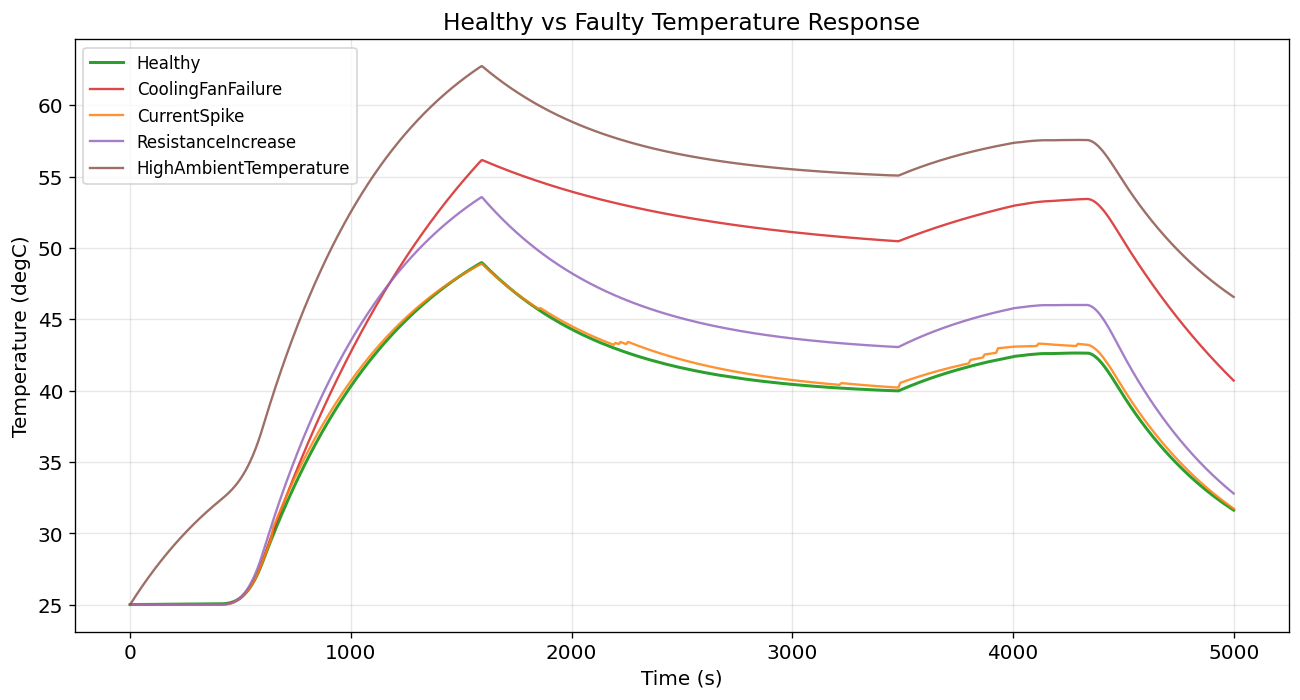

In [17]:
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(healthy_df["Time_s"], healthy_df["TrueTemperature_C"],
        label="Healthy", color="tab:green", linewidth=1.8)

fault_colors = {
    "CoolingFanFailure": "tab:red",
    "CurrentSpike": "tab:orange",
    "ResistanceIncrease": "tab:purple",
    "HighAmbientTemperature": "tab:brown",
}
for fault_name, d in fault_specs.items():
    ax.plot(d["time"], d["temperature"], label=fault_name,
            color=fault_colors[fault_name], linewidth=1.4, alpha=0.85)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Temperature (degC)")
ax.set_title("Healthy vs Faulty Temperature Response")
ax.legend(loc="upper left", fontsize=10)
fig.tight_layout()
fig.savefig("figure1_healthy_vs_faulty_temperature.png")
plt.show()

### Figure 2 — Actual vs Predicted Temperature (per scenario)

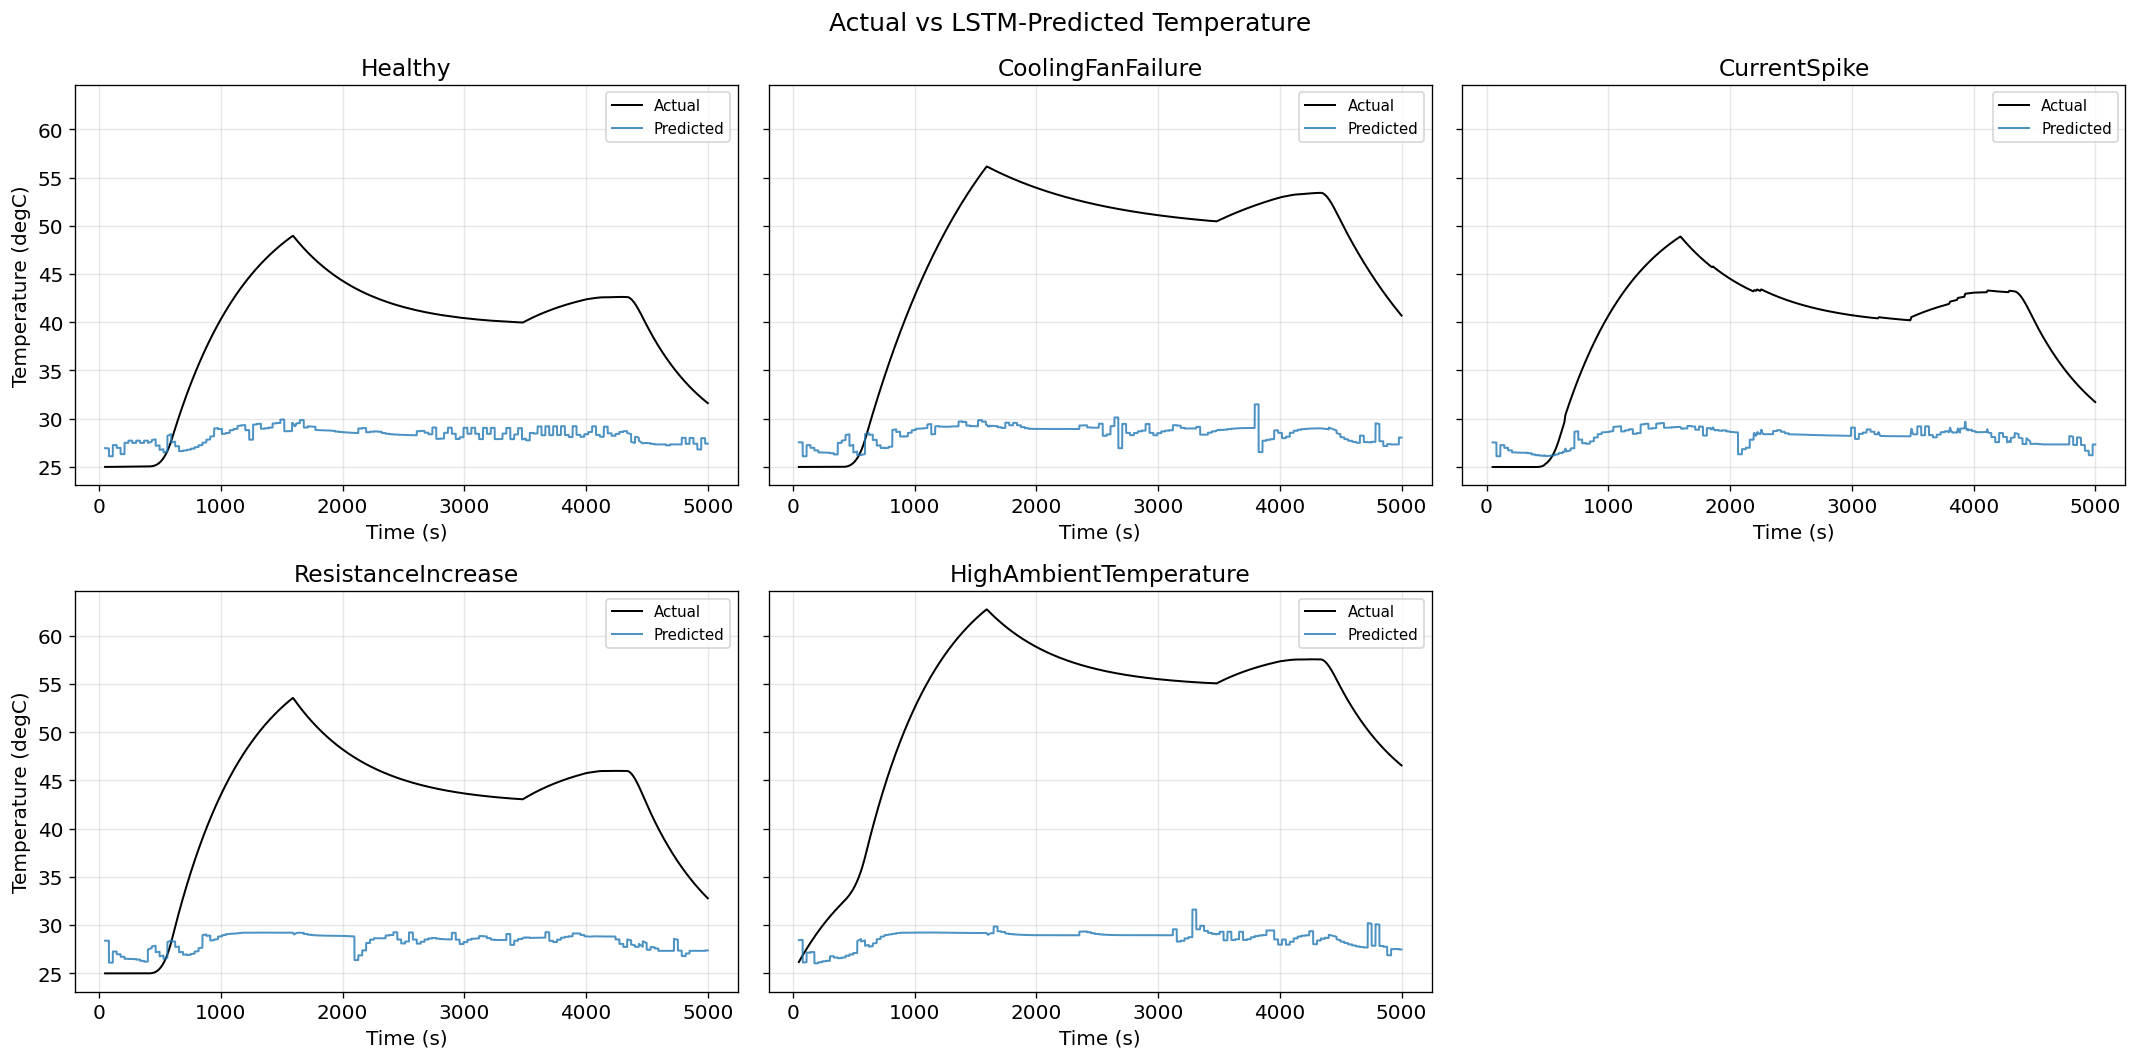

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharey=True)
axes = axes.flatten()

scenarios = [("Healthy", healthy_df["Time_s"].values[idx_healthy], y_healthy, pred_healthy)]
for fault_name, d in fault_windows.items():
    scenarios.append((fault_name, d["df"]["Time_s"].values[d["idx"]], d["y"], pred_faults[fault_name]))

for ax, (name, t, y_true, y_pred) in zip(axes, scenarios):
    ax.plot(t, y_true, label="Actual", color="black", linewidth=1.2)
    ax.plot(t, y_pred, label="Predicted", color="tab:blue", linewidth=1.2, alpha=0.8)
    ax.set_title(name)
    ax.set_xlabel("Time (s)")
    ax.legend(fontsize=9)

axes[0].set_ylabel("Temperature (degC)")
axes[3].set_ylabel("Temperature (degC)")
for ax in axes[len(scenarios):]:
    ax.axis("off")

fig.suptitle("Actual vs LSTM-Predicted Temperature", fontsize=15)
fig.tight_layout()
fig.savefig("figure2_actual_vs_predicted_temperature.png")
plt.show()

### Figure 3 — Prediction Error With Threshold

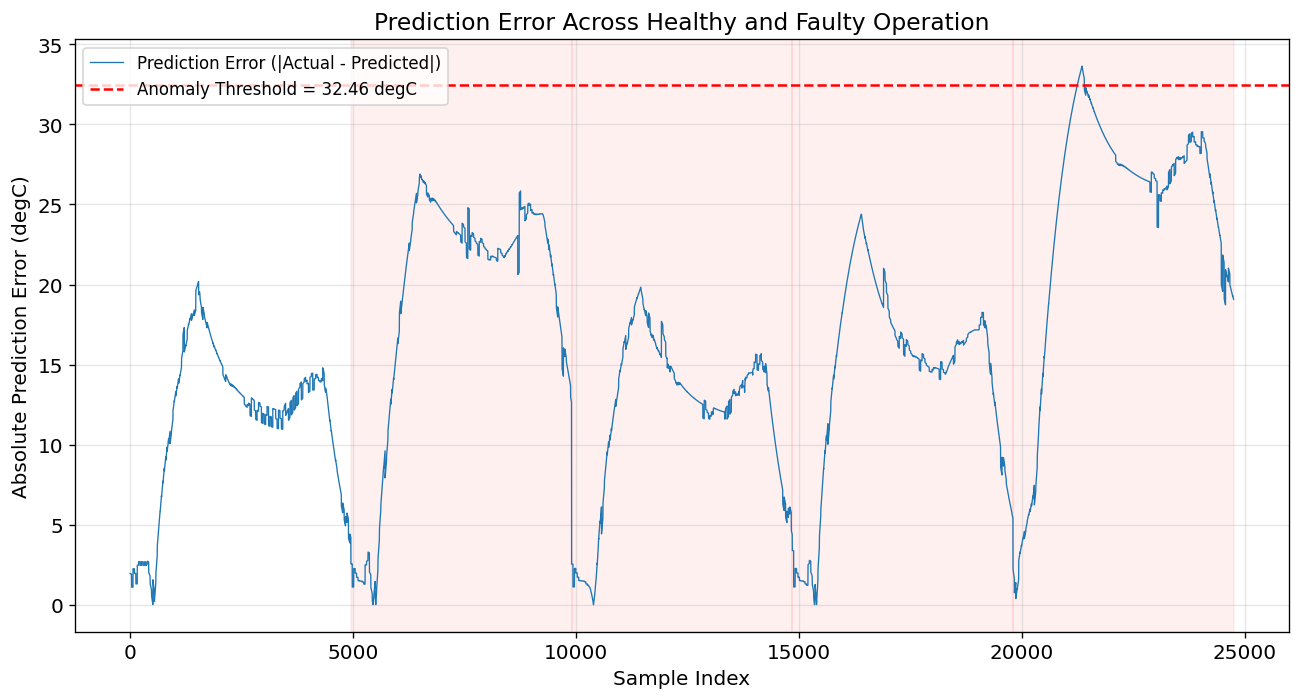

In [19]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(results_df.index, results_df["PredictionError"], color="tab:blue",
        linewidth=0.8, label="Prediction Error (|Actual - Predicted|)")
ax.axhline(ANOMALY_THRESHOLD, color="red", linestyle="--", linewidth=1.5,
           label=f"Anomaly Threshold = {ANOMALY_THRESHOLD:.2f} degC")

# Shade fault-type regions for readability
boundaries = results_df.reset_index().groupby("FaultType", sort=False)["index"].agg(["min", "max"])
for fault_type, row in boundaries.iterrows():
    if fault_type != "Healthy":
        ax.axvspan(row["min"], row["max"], alpha=0.06, color="red")

ax.set_xlabel("Sample Index")
ax.set_ylabel("Absolute Prediction Error (degC)")
ax.set_title("Prediction Error Across Healthy and Faulty Operation")
ax.legend(loc="upper left", fontsize=10)
fig.tight_layout()
fig.savefig("figure3_prediction_error_with_threshold.png")
plt.show()

### Figure 4 — Detected Anomalies Highlighted

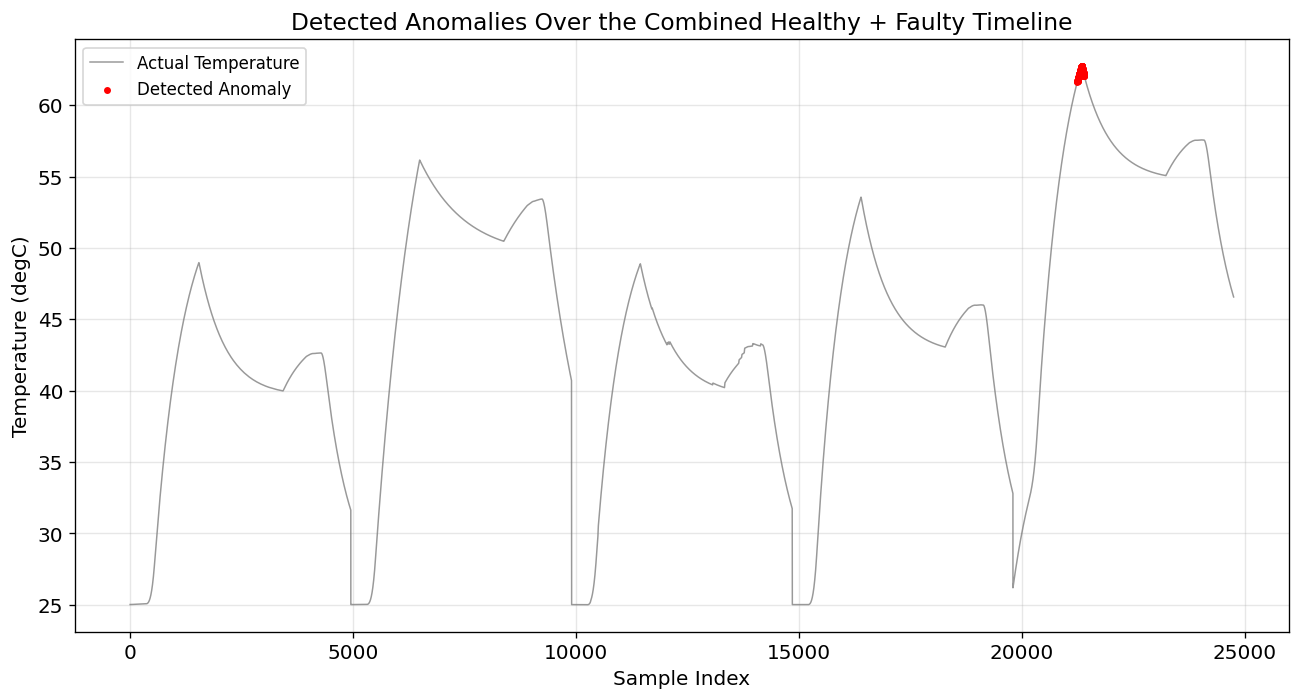

In [20]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(results_df.index, results_df["TrueTemperature_C"], color="gray",
        linewidth=0.9, label="Actual Temperature", alpha=0.8)

anomaly_mask = results_df["DetectedAnomaly"] == 1
ax.scatter(results_df.index[anomaly_mask], results_df["TrueTemperature_C"][anomaly_mask],
           color="red", s=10, label="Detected Anomaly", zorder=5)

ax.set_xlabel("Sample Index")
ax.set_ylabel("Temperature (degC)")
ax.set_title("Detected Anomalies Over the Combined Healthy + Faulty Timeline")
ax.legend(loc="upper left", fontsize=10)
fig.tight_layout()
fig.savefig("figure4_detected_anomalies.png")
plt.show()

### Figure 5 — Confusion Matrix

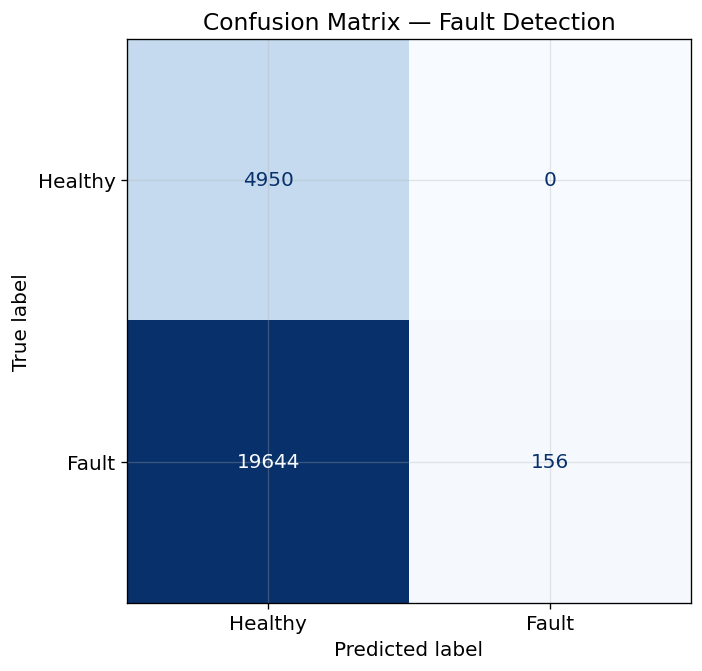

In [21]:
fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Healthy", "Fault"])
disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Confusion Matrix — Fault Detection")
fig.tight_layout()
fig.savefig("figure5_confusion_matrix.png")
plt.show()

### Figure 6 — Detection Rate by Fault Type

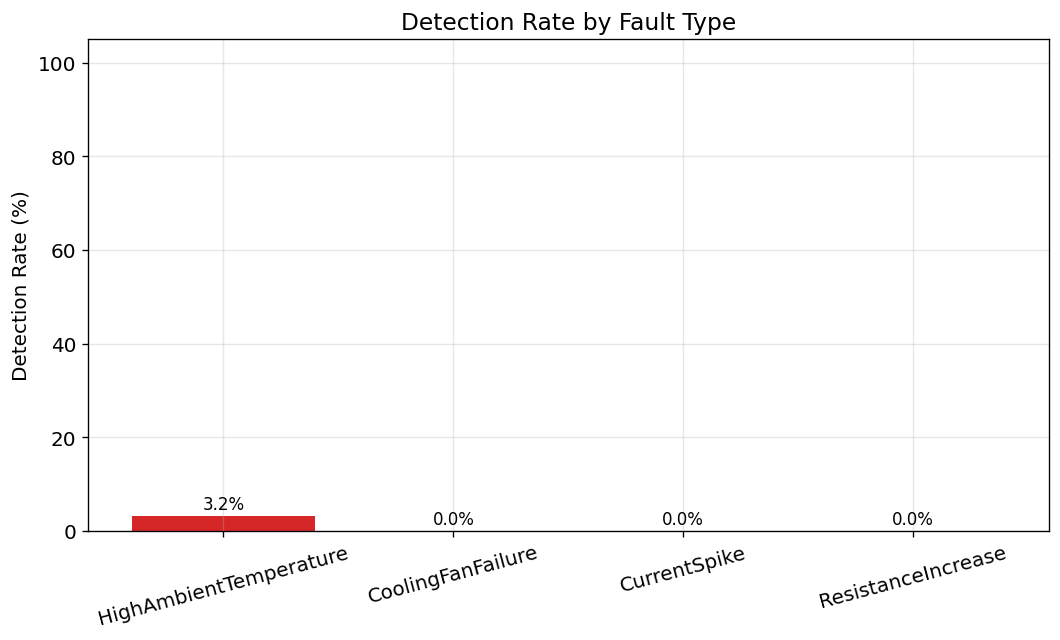

In [22]:
fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(per_fault_rate.index, per_fault_rate.values,
              color=["tab:red", "tab:orange", "tab:purple", "tab:brown"][:len(per_fault_rate)])
ax.set_ylabel("Detection Rate (%)")
ax.set_title("Detection Rate by Fault Type")
ax.set_ylim(0, 105)
for bar, val in zip(bars, per_fault_rate.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 1.5, f"{val:.1f}%",
            ha="center", fontsize=10)
plt.xticks(rotation=15)
fig.tight_layout()
fig.savefig("figure6_detection_rate_by_fault_type.png")
plt.show()

## 13. Engineering Discussion

**Why each fault increases prediction error**

The LSTM model was trained exclusively on healthy operating dynamics — it has learned
the mapping between current draw and the *normal* thermal response of the magnet power
supply. Each fault perturbs a different physical mechanism inside the thermal model,
which shifts the true temperature trajectory away from what the model has learned to
expect for the observed current:

- **Cooling Fan Failure** lowers the effective cooling coefficient, so heat generated by
  the coil current is no longer removed at the expected rate. Temperature drifts upward
  even though current stays nominal, producing a growing residual as the gap between the
  model's learned (healthy) thermal response and the true, poorly-cooled response widens.
- **Current Spike** briefly increases $I^2R$ heating far beyond the range of current
  values the model associates with a given temperature trend, producing sharp, localized
  residual spikes coincident with each current burst.
- **Resistance Increase** raises the resistive heating term for the *same* current,
  something the healthy model has never observed — identical current now produces
  systematically higher temperatures than the model predicts.
- **High Ambient Temperature** shifts the entire thermal equilibrium upward. Since the
  model was never exposed to a 40 degC ambient condition, its baseline prediction under-
  or over-shoots depending on current, producing a sustained residual offset rather than
  the healthy fluctuation pattern.

**Why the LSTM detects abnormal behaviour**

The LSTM was trained to capture the *temporal* and *nonlinear* relationship between
recent current history and the resulting temperature under nominal thermal physics.
Because none of the four fault mechanisms are represented in its training distribution,
the model continues to extrapolate the *healthy* response from the observed current —
so whenever the true (faulty) physics diverges from the healthy physics, the residual
between actual and predicted temperature grows past the statistical threshold learned
from healthy-operation noise (Notebook 3), triggering an anomaly flag. This is exactly
the model-based (rather than purely statistical) anomaly detection principle: the model
encodes "normal" system dynamics, and any physically-driven deviation from those dynamics
surfaces as a residual anomaly.

**Industrial significance**

Magnet power supplies in accelerator and large-scale magnet facilities operate under
tight thermal margins; a slow cooling degradation or conductor ageing effect can go
unnoticed by simple threshold alarms on temperature alone (since these thresholds are
often static and conservative). A model-based residual detector is sensitive to *how*
the temperature responds to current, not merely its absolute value — allowing much
earlier detection of gradually developing faults such as cooling degradation or
resistance drift, well before an absolute over-temperature trip would occur.

**Advantages of predictive maintenance**

Detecting these fault signatures early enables condition-based maintenance rather than
reactive or purely time-based maintenance: cooling fans can be serviced before a full
failure, ageing conductors can be scheduled for replacement, and current-quality issues
upstream can be investigated — all before they cause a forced outage, in turn reducing
unplanned downtime, protecting the magnet coil from thermal stress, and lowering overall
maintenance cost.

**Relationship with the research paper methodology**

This notebook mirrors the physics-based digital-twin + LSTM residual-thresholding
validation methodology used in the reference research paper: a calibrated first-
principles thermal model generates realistic healthy and faulty operating data, a
data-driven temporal model (LSTM) learns the healthy dynamics, and fault detection is
performed by thresholding the residual between the physics-based ground truth and the
learned model's prediction — with performance quantified via precision, recall, F1
score, and detection rate per fault type, exactly as reported in the paper's validation
section.

## 14. Output Files

The following files are produced by this notebook:

- `faulty_magnet_power_supply_dataset.csv` — the four physics-based fault scenarios.
- `fault_validation_results.csv` — combined healthy + faulty prediction/anomaly results.
- `figure1_healthy_vs_faulty_temperature.png`
- `figure2_actual_vs_predicted_temperature.png`
- `figure3_prediction_error_with_threshold.png`
- `figure4_detected_anomalies.png`
- `figure5_confusion_matrix.png`
- `figure6_detection_rate_by_fault_type.png`